In [1]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

iris = load_iris()
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = pd.DataFrame(data = iris.data, columns = feature_names)
kmeans = KMeans(n_clusters = 3, init = "k-means++", max_iter = 300,
                random_state=0).fit(df)
df["cluster"] = kmeans.labels_

score_samples = silhouette_samples(iris.data, df["cluster"])
print("silhouette_samples의 리턴값의 모양", score_samples.shape)

df["silhouette_coeff"] = score_samples

average_score = silhouette_score(iris.data, df["cluster"])
print("실루엣점수", np.round(average_score, 3))

df.head()

silhouette_samples의 리턴값의 모양 (150,)
실루엣점수 0.553


,sepal_length,sepal_width,petal_length,petal_width,cluster,silhouette_coeff
0,5.1,3.5,1.4,0.2,1,0.852955
1,4.9,3.0,1.4,0.2,1,0.815495
2,4.7,3.2,1.3,0.2,1,0.829315
3,4.6,3.1,1.5,0.2,1,0.805014
4,5.0,3.6,1.4,0.2,1,0.849302


In [2]:
df.groupby("cluster")["silhouette_coeff"].mean()

cluster
0    0.417320
1    0.798140
2    0.451105
Name: silhouette_coeff, dtype: float64

In [3]:
def visualize_silhouette(cluster_lists, X_features):
    import matplotlib.cm as cm

    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize = (4 * n_cols, 4), nrows = 1,
                            ncols = n_cols)
    for ind, n_cluster in enumerate(cluster_lists):
        clusterer = KMeans(n_clusters= n_cluster, max_iter = 500, random_state=0)
        cluster_labels = clusterer.fit_predict(X_features)

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[ind].set_title("No. of Cluster :"+str(n_cluster)+"\n" \
                           "silhouette score:" "+str(round(sil_avg, 3))")
        axs[ind].set_xlabel("The 실루엣 coeff values")
        axs[ind].set_ylabel("Cluster Label")
        axs[ind].set_xlim([-.01, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels == i]
            ith_cluster_sil_values.sort()

            size_cluster_1 = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_1

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0,
                                  ith_cluster_sil_values, facecolor = color,
                                  edgecolor = color, alpha = 0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_1, str(i))
            y_lower = y_upper + 10
        axs[ind].axvline(x = sil_avg, color = "red", linestyle = "--")

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 50659 (\N{HANGUL SYLLABLE ES}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47336 (\N{HANG

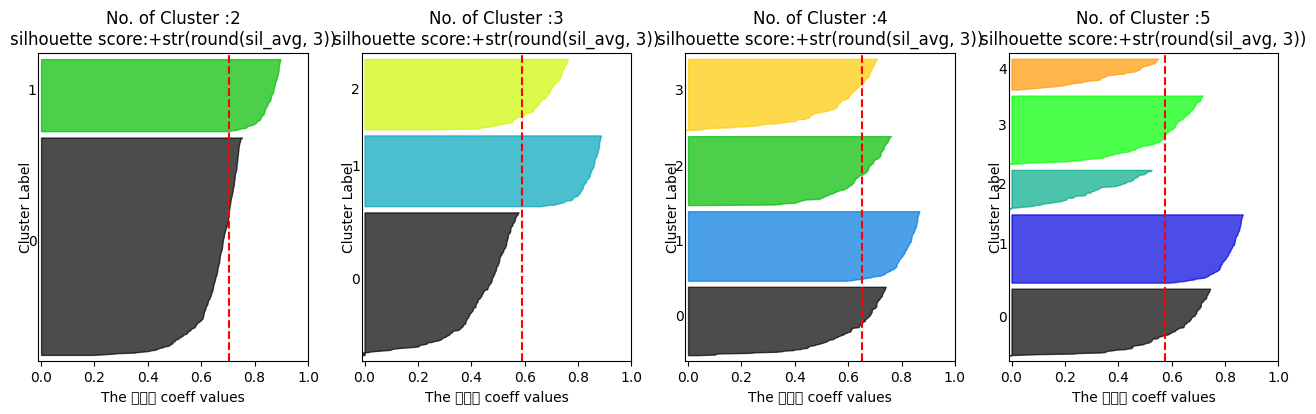

In [4]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples = 500, n_features = 2, centers = 4,
                   cluster_std = 1, center_box = (-10.0, 10.0),
                   shuffle = True, random_state=1)
visualize_silhouette([2, 3, 4, 5], X)

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 47336 (\N{HANGUL SYLLABLE RU}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 50659 (\N{HANGUL SYLLABLE ES}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47336 (\N{HANG

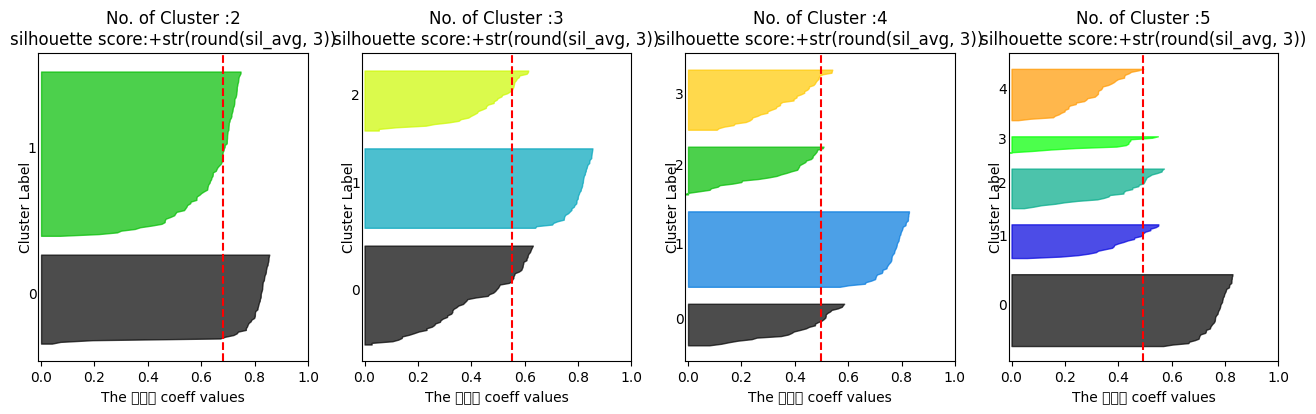

In [5]:
from sklearn.datasets import load_iris

iris = load_iris()
visualize_silhouette([2, 3, 4, 5], iris.data)